# Reproduce Figures — "Contrast encodes inductive bias..."

Regenerates every figure from the paper (arXiv:2606.07770) from the data
shipped in this repository. No GPU required, no W&B account, no internet
access needed except to (optionally) re-download the pendulum dataset from
Zenodo if `dvsib_pendulum_experiments/data/` isn't already populated.

**Run this notebook from the `notebooks/` directory** (its own location) —
all paths below are relative to that.

Figure map:
- **Fig 2** (main text): combined noise-strength sweep, both datasets
- **Fig 3**: pendulum 2-D embeddings (kz=2), ATN vs WTN x {no/changing/fixed noise}
- **Fig 4**: moving-dot RMSE vs correlation time τ (fixed T=17)
- **Fig 5**: moving-dot (τ, T) phase diagram + peak-error scaling
- **Fig S1**: pendulum latent trajectories
- **Fig S2**: stability to hyperparameters/seeds (5-best-trial band)
- **Fig S3**: hyperparameter variability of the τ-sweep
- **Fig S4**: τ/T rescaling collapse
- **Fig S5**: WTN peak-error power-law scaling vs T
- **Fig S6**: example frames from both datasets

Fig 1 (architecture schematic) is a static TikZ diagram, not reproduced here.


## Setup

In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = Path("..").resolve()
DOT_DIR = REPO / "jepa_simclr_dot_experiments"
PEND_DIR = REPO / "dvsib_pendulum_experiments"
FIGURE_DIR = Path("Figures")
FIGURE_DIR.mkdir(exist_ok=True)

# NOTE on import order: dvsib_pendulum_experiments/data.py (a plain module) and
# jepa_simclr_dot_experiments/data/ (a package) share the name "data". Import
# the moving-dot data package FIRST, while only DOT_DIR is on sys.path, so
# `import data` can't resolve to the pendulum's data.py instead.
sys.path.insert(0, str(DOT_DIR))
import data as dot_data                       # jepa_simclr_dot_experiments/data

sys.path.insert(0, str(PEND_DIR))
# NOTE on a second, analogous name collision: jepa_simclr_dot_experiments/models.py
# and dvsib_pendulum_experiments/models.py also share a name. This notebook only
# ever imports the pendulum side's `models`, so it's never actually ambiguous here
# -- but if a future cell needs jepa's models.py too, don't add a bare
# `import models` for it: sys.modules['models'] will already be cached as this
# (pendulum) module and a second import will silently return the wrong one. Load
# it explicitly instead, e.g. via importlib.util.spec_from_file_location keyed to
# DOT_DIR / "models.py" (see dvsib_pendulum_experiments/run_sweep.py's
# `_pendulum_data_module` for the same pattern applied to the `data` collision).
from models import DVSIB                      # dvsib_pendulum_experiments
from noise import add_ou_noise_per_trajectory
from training import encode_dataset
from run_sweep import load_data, make_phys_tensors

NORM = 28.0  # moving-dot RMSE normalization (image side length)
DEVICE = "cpu"

VLABEL = {"baseline": "ATN", "baseline_traj_neg": "WTN"}
COLOR = {"baseline": "tab:blue", "baseline_traj_neg": "tab:orange"}


## Load shipped data

Everything below reads only from files already in this repository — no
W&B API calls, no live HDF5 sweep files. The only network access that may
happen is `load_data()` triggering `data.py`'s Zenodo download on first run,
if `dvsib_pendulum_experiments/data/` doesn't already exist.

In [ ]:
# Moving-dot (W&B export)
# NOTE: sweep_metrics_fig2a.csv's noise-strength column is named "alpha"
# (values ~0.5-3.0). This is a naming holdover from an earlier version of
# this dataset/pipeline, predating the introduction of OU temporal-
# correlation noise -- back then there was only one noise-strength
# parameter, informally called "alpha", and no separate correlation
# parameter existed to disambiguate it from. Once OU noise was added, a
# second parameter for the correlation coefficient was introduced under the
# name `noise_alpha`/`ou_alpha` (range [0,1]) -- see `tau_df["noise_alpha"]`
# just below, and `dataset_noise`/`dataset_noise_alpha` elsewhere in this
# codebase. This particular CSV was never re-exported with the newer names.
# Convention for any newly generated CSV: `noise_alpha`/`ou_alpha` means the
# OU correlation coefficient in [0,1]; noise amplitude/strength should be
# named `sigma`/`noise`/`dataset_noise` -- never `alpha`.
dot_df = pd.read_csv(DOT_DIR / "results" / "sweep_metrics_fig2a.csv")
dot_sup_df = pd.read_csv(DOT_DIR / "results" / "supervised_baseline.csv")
tau_df = pd.read_csv(DOT_DIR / "results" / "sweep_metrics_tau.csv")
MAX_STEP, DOT_STD = 4.0, 1.3
tau_df = tau_df.query("max_step == @MAX_STEP and dot_std == @DOT_STD").copy()
tau_df["tau"] = -1.0 / np.log(tau_df["noise_alpha"].replace(0, np.nan))

# Pendulum (extracted sweep metrics)
pend_df = pd.read_csv(PEND_DIR / "figure_data" / "sweep_metrics.csv")
pend_sup_df = pd.read_csv(PEND_DIR / "figure_data" / "supervised_baseline.csv")

# Pendulum raw pixel data (downloads from Zenodo on first call if not cached)
data_clean, phys = load_data(str(PEND_DIR / "data"))
fvars = make_phys_tensors(phys, num_frames=2)
theta_deg_full = np.rad2deg(np.angle(np.exp(1j * fvars["theta"].numpy())))

print(f"dot_df: {len(dot_df)} rows | tau_df: {len(tau_df)} rows | "
      f"pend_df: {len(pend_df)} rows | pendulum pixels: {tuple(data_clean.shape)}")


## Aggregation helpers

Each sweep condition was run with many random hyperparameter trials. Per the
paper (Appendix A.2), main-text figures (2, 4, 5) report the single best
trial (`min` aggregation); the corresponding appendix figures (S2, S3) show
the same data as a band over the 5 best trials (`kmin_range`), to confirm
the main-text result isn't a hyperparameter fluke.

In [16]:
def min_agg(df, group_cols):
    return df.groupby(group_cols)["rmse_enc"].min().reset_index()


def kmin_range_agg(df, group_cols, ycol="rmse_enc", k=5):
    def _s(s):
        vals = s.dropna().nsmallest(k)
        return pd.Series({"median": vals.median(), "lo": vals.min(), "hi": vals.max()})
    return df.groupby(group_cols)[ycol].apply(_s).unstack().reset_index()


## Fig 2 (main text) / Fig S2 (appendix): combined noise-strength sweep

Probe RMSE as noise strength increases, for both datasets and both
negative-sampling strategies (ATN vs. WTN), split into changing- and
fixed-noise conditions. Shows that ATN fails under fixed noise while WTN
tracks the supervised baseline in both noise regimes.

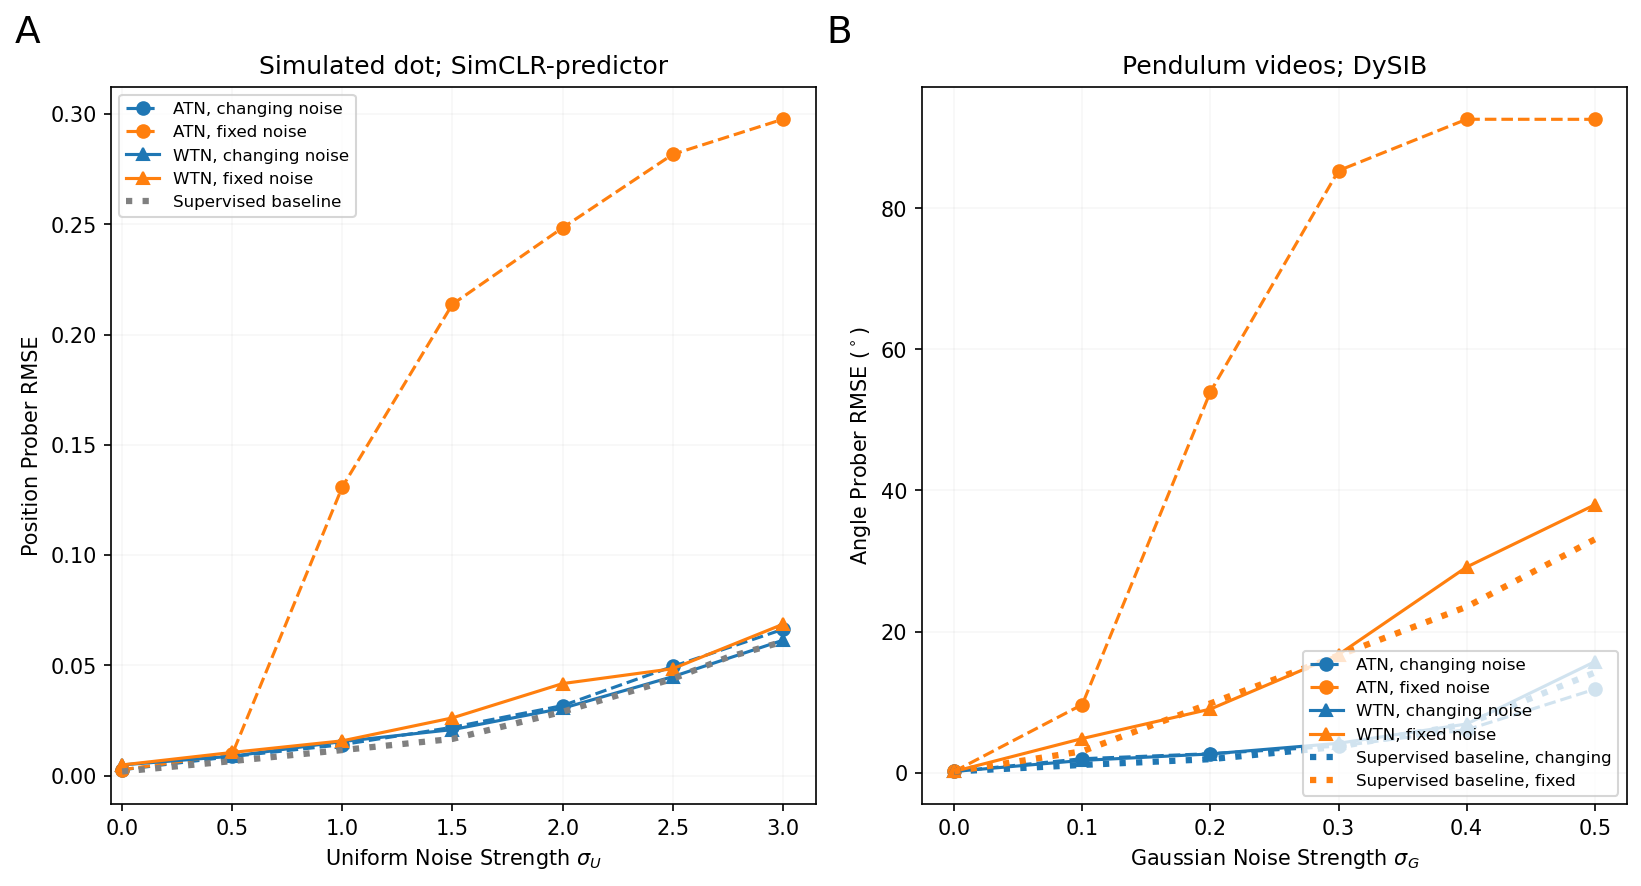

In [17]:
T_FIXED = 17


def _dot_condition_with_clean(variant, noise_cfg, agg_mode, k=5):
    """Duplicate the alpha=0 'clean' condition into both changing/fixed curves."""
    sub = dot_df.query("variant == @variant and T == @T_FIXED").copy()
    clean = sub[(sub["noise_cfg"] == "clean") & (sub["alpha"] == 0.0)].copy()
    clean["noise_cfg"] = noise_cfg
    merged = pd.concat([sub[sub["noise_cfg"] == noise_cfg], clean], ignore_index=True)
    if agg_mode == "min":
        return min_agg(merged, ["alpha"]).rename(columns={"rmse_enc": "mean"})
    return kmin_range_agg(merged, ["alpha"], k=k)


def _pend_condition(neg_mode, ou_alpha, agg_mode, k=5):
    sub = pend_df.query("ndims == 8 and neg_mode == @neg_mode").copy()
    sub = sub[np.isclose(sub["ou_alpha"], ou_alpha)]
    if agg_mode == "min":
        return min_agg(sub.rename(columns={"theta_test_deg": "rmse_enc"}), ["sigma"]).rename(columns={"rmse_enc": "mean"})
    return kmin_range_agg(sub.rename(columns={"theta_test_deg": "rmse_enc"}), ["sigma"], k=k)


def make_fig2(agg_mode, out_name, k=5):
    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(11, 6.0), dpi=150)

    dot_lines = [
        (_dot_condition_with_clean("baseline", "changing_config", agg_mode, k), "tab:blue", "--", "o", "ATN, changing noise"),
        (_dot_condition_with_clean("baseline", "fixed_config", agg_mode, k), "tab:orange", "--", "o", "ATN, fixed noise"),
        (_dot_condition_with_clean("baseline_traj_neg", "changing_config", agg_mode, k), "tab:blue", "-", "^", "WTN, changing noise"),
        (_dot_condition_with_clean("baseline_traj_neg", "fixed_config", agg_mode, k), "tab:orange", "-", "^", "WTN, fixed noise"),
    ]

    def _plot(ax, lines, xcol, norm):
        for sub, color, ls, marker, label in lines:
            if len(sub) == 0:
                continue
            x = sub[xcol].to_numpy(dtype=float)
            if agg_mode == "min":
                ax.plot(x, sub["mean"].to_numpy(dtype=float) / norm, color=color, ls=ls, marker=marker, markersize=6, label=label)
            else:
                y_lo, y_hi = sub["lo"].to_numpy(dtype=float) / norm, sub["hi"].to_numpy(dtype=float) / norm
                ax.fill_between(x, y_lo, y_hi, color=color, alpha=0.15)
                ax.plot(x, sub["median"].to_numpy(dtype=float) / norm, color=color, ls=ls, marker=marker, markersize=6, label=label)

    _plot(ax_a, dot_lines, "alpha", NORM)
    dsup = min_agg(dot_sup_df, ["sigma"]).rename(columns={"rmse_enc": "mean"}) if agg_mode == "min" else kmin_range_agg(dot_sup_df, ["sigma"], k=k)
    ycol = "mean" if agg_mode == "min" else "median"
    ax_a.plot(dsup["sigma"], dsup[ycol] / NORM, color="gray", ls=":", lw=3, label="Supervised baseline")
    ax_a.set_xlabel(r"Uniform Noise Strength $\sigma_U$"); ax_a.set_ylabel("Position Prober RMSE")
    ax_a.set_title("Simulated dot; SimCLR-predictor"); ax_a.grid(alpha=0.1); ax_a.set_xlim(left=-0.05)

    pend_lines = [
        (_pend_condition("time", 0.0, agg_mode, k), "tab:blue", "--", "o", "ATN, changing noise"),
        (_pend_condition("time", 1.0, agg_mode, k), "tab:orange", "--", "o", "ATN, fixed noise"),
        (_pend_condition("traj", 0.0, agg_mode, k), "tab:blue", "-", "^", "WTN, changing noise"),
        (_pend_condition("traj", 1.0, agg_mode, k), "tab:orange", "-", "^", "WTN, fixed noise"),
    ]
    _plot(ax_b, pend_lines, "sigma", 1.0)
    pend_sigma_max = pend_df["sigma"].max()  # supervised baseline was swept further (to 0.7) than
                                              # the ATN/WTN sweep (to 0.5); restrict to the same range
    for ou_alpha, color, label in [(0.0, "tab:blue", "Supervised baseline, changing"), (1.0, "tab:orange", "Supervised baseline, fixed")]:
        sub = pend_sup_df[np.isclose(pend_sup_df["ou_alpha"], ou_alpha) & (pend_sup_df["sigma"] <= pend_sigma_max)].rename(columns={"best_theta_test_deg": "rmse_enc"})
        agg = min_agg(sub, ["sigma"]).rename(columns={"rmse_enc": "mean"}) if agg_mode == "min" else kmin_range_agg(sub, ["sigma"], k=k)
        if len(agg) == 0:
            continue
        ax_b.plot(agg["sigma"], agg[ycol], color=color, ls=":", lw=3, label=label)
    ax_b.set_xlabel(r"Gaussian Noise Strength $\sigma_G$"); ax_b.set_ylabel(r"Angle Prober RMSE ($^\circ$)")
    ax_b.set_title("Pendulum videos; DySIB"); ax_b.grid(alpha=0.1)

    for ax, lbl in [(ax_a, "A"), (ax_b, "B")]:
        ax.text(-0.10, 1.05, lbl, transform=ax.transAxes, fontsize=18, va="bottom", ha="right")
    ax_a.legend(fontsize=8, loc="upper left"); ax_b.legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"{out_name}.png", dpi=150, bbox_inches="tight")
    plt.show()


make_fig2("min", "fig2_main")


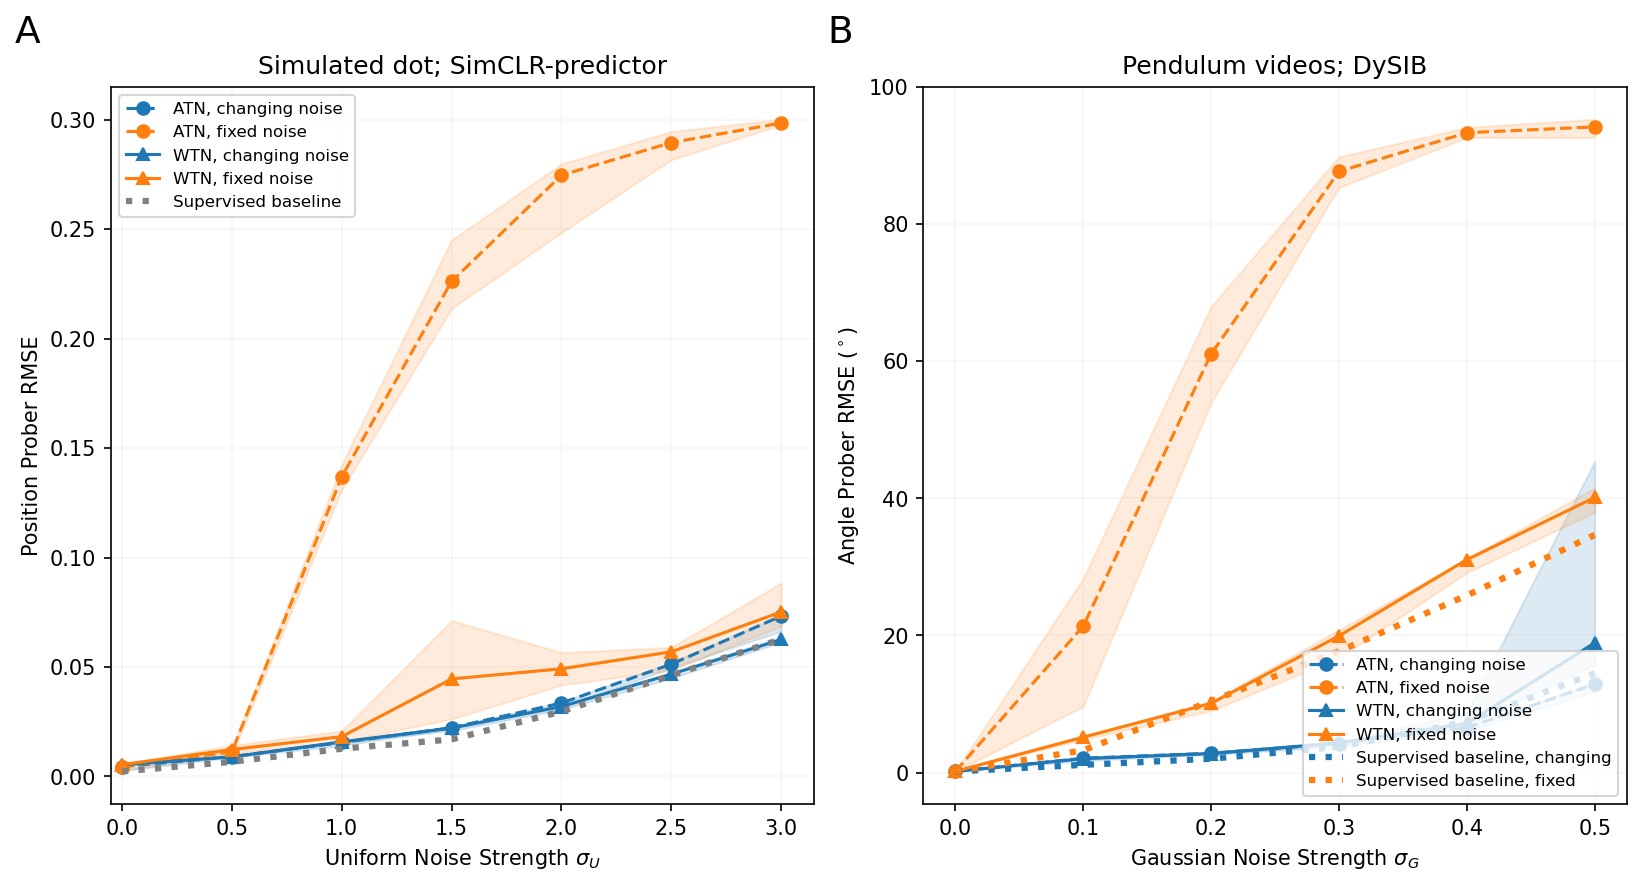

In [18]:
make_fig2("kmin_range", "figS2_appendix")

## Fig 3 / Fig S1: pendulum embeddings and latent trajectories

2-D DySIB latent space (kz=2) for the pendulum, colored by the true angle
(Fig 3), and the connected per-trajectory paths through that same latent
space (Fig S1). Under fixed noise, ATN collapses the representation into
disconnected per-trajectory clusters; WTN preserves the ring structure that
tracks the true angle.

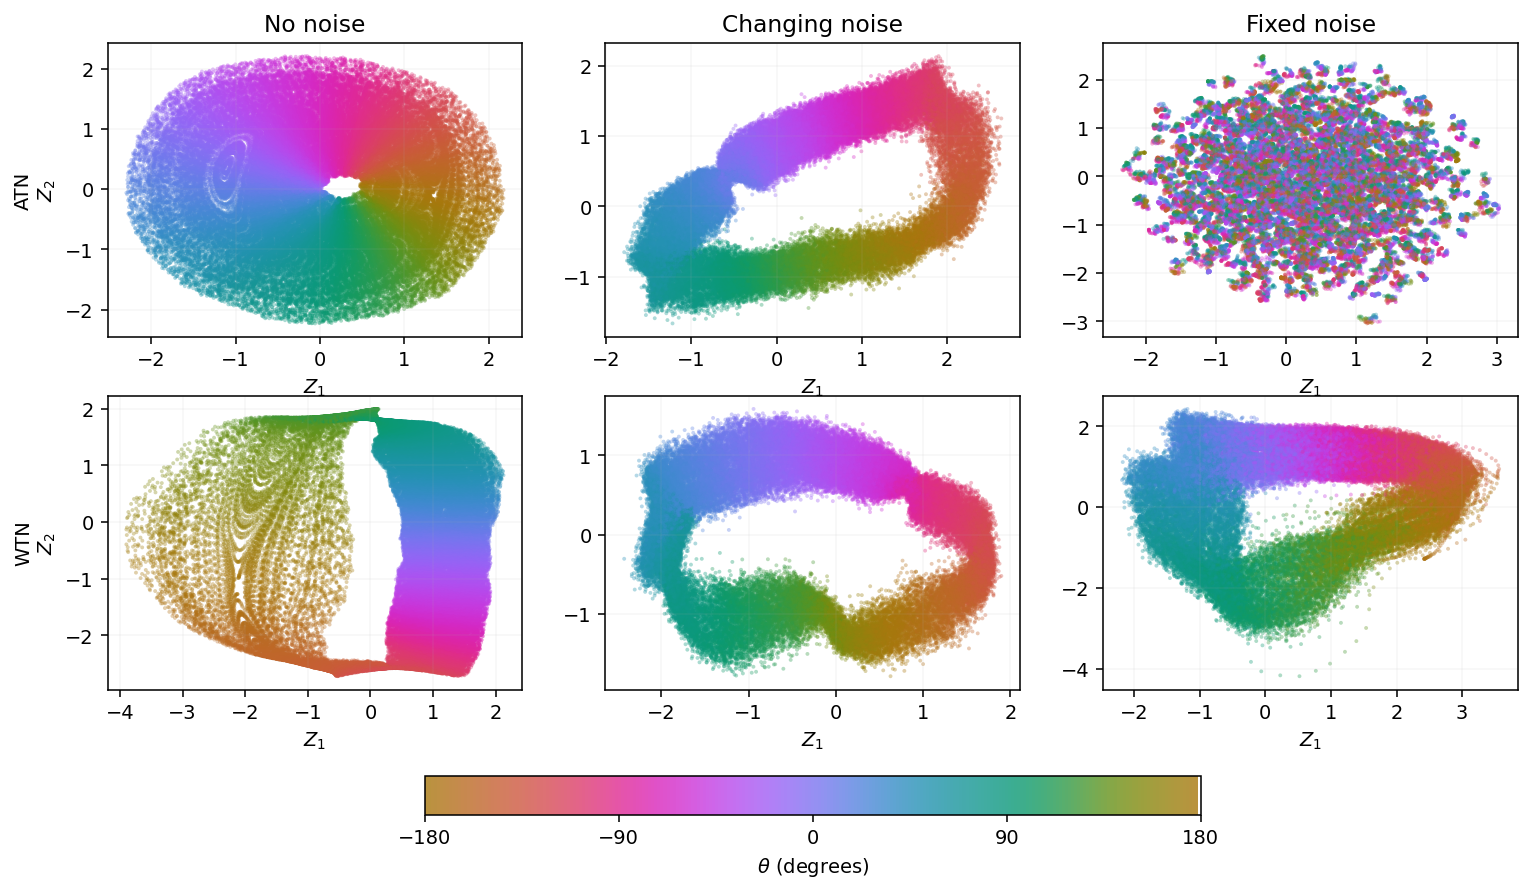

In [19]:
CKPT = {
    ("time", "clean"):     "kz2_negtime_sig0.0_alpha0.0_rep5.pt",
    ("time", "changing"):  "kz2_negtime_sig0.2_alpha0.0_rep5.pt",
    ("time", "fixed"):     "kz2_negtime_sig0.2_alpha1.0_rep5.pt",
    ("traj", "clean"):     "kz2_negtraj_sig0.0_alpha0.0_rep6.pt",
    ("traj", "changing"):  "kz2_negtraj_sig0.2_alpha0.0_rep5.pt",
    ("traj", "fixed"):     "kz2_negtraj_sig0.2_alpha1.0_rep5.pt",
}


def _load_checkpoint(name):
    ck = torch.load(PEND_DIR / "checkpoints" / name, weights_only=False)
    p = ck["params"]
    model = DVSIB(input_dim=int(p["input_dim"]), dz=int(p["ndims"]), dzf=32,
                  num_frames=int(p["num_frames"]), gamma=float(p["gamma"]), neg_mode=str(p["neg_mode"]))
    model.load_state_dict(ck["state_dict"])
    model.eval()
    return model, p


def _encode(name, subsample=100_000, seed=0):
    model, p = _load_checkpoint(name)
    noisy = add_ou_noise_per_trajectory(data_clean, sigma=float(p["sigma"]), ou_alpha=float(p["ou_alpha"]),
                                         clip=(0.0, 1.0), seed=int(p["noise_seed"]), init="stationary")
    zx, numD = encode_dataset(model, noisy, num_frames=int(p["num_frames"]), device=DEVICE)
    zx = zx.numpy()
    rng = np.random.default_rng(seed)
    idx = rng.choice(zx.shape[0], size=min(subsample, zx.shape[0]), replace=False)
    return zx[idx], theta_deg_full[idx], numD


try:
    import cmocean
    PHASE_CMAP = cmocean.cm.phase
except ImportError:
    PHASE_CMAP = plt.cm.hsv

fig3, axes3 = plt.subplots(2, 3, figsize=(13, 8), dpi=140)
cols, col_titles = ["clean", "changing", "fixed"], ["No noise", "Changing noise", "Fixed noise"]
rows, row_labels = ["time", "traj"], ["ATN", "WTN"]
vmin3, vmax3 = theta_deg_full.min(), theta_deg_full.max()
sc = None
for ri, neg_mode in enumerate(rows):
    for ci, cond in enumerate(cols):
        ax = axes3[ri, ci]
        z, th, numD = _encode(CKPT[(neg_mode, cond)])
        sc = ax.scatter(z[:, 0], z[:, 1], c=th, s=4, alpha=0.35, linewidths=0,
                        cmap=PHASE_CMAP, vmin=vmin3, vmax=vmax3, rasterized=True)
        if ri == 0: ax.set_title(col_titles[ci])
        if ci == 0: ax.set_ylabel(f"{row_labels[ri]}\n$Z_2$")
        ax.set_xlabel("$Z_1$"); ax.grid(alpha=0.1)
cbar3 = fig3.colorbar(sc, ax=axes3, orientation="horizontal", location="bottom",
                      shrink=0.55, pad=0.1, anchor=(0.5, 1.0))
cbar3.solids.set_alpha(0.8)
cbar3.set_label(r"$\theta$ (degrees)")
cbar3.set_ticks([-180, -90, 0, 90, 180])
fig3.savefig(FIGURE_DIR / "fig3_pendulum_embeddings.png", dpi=150, bbox_inches="tight")
plt.show()


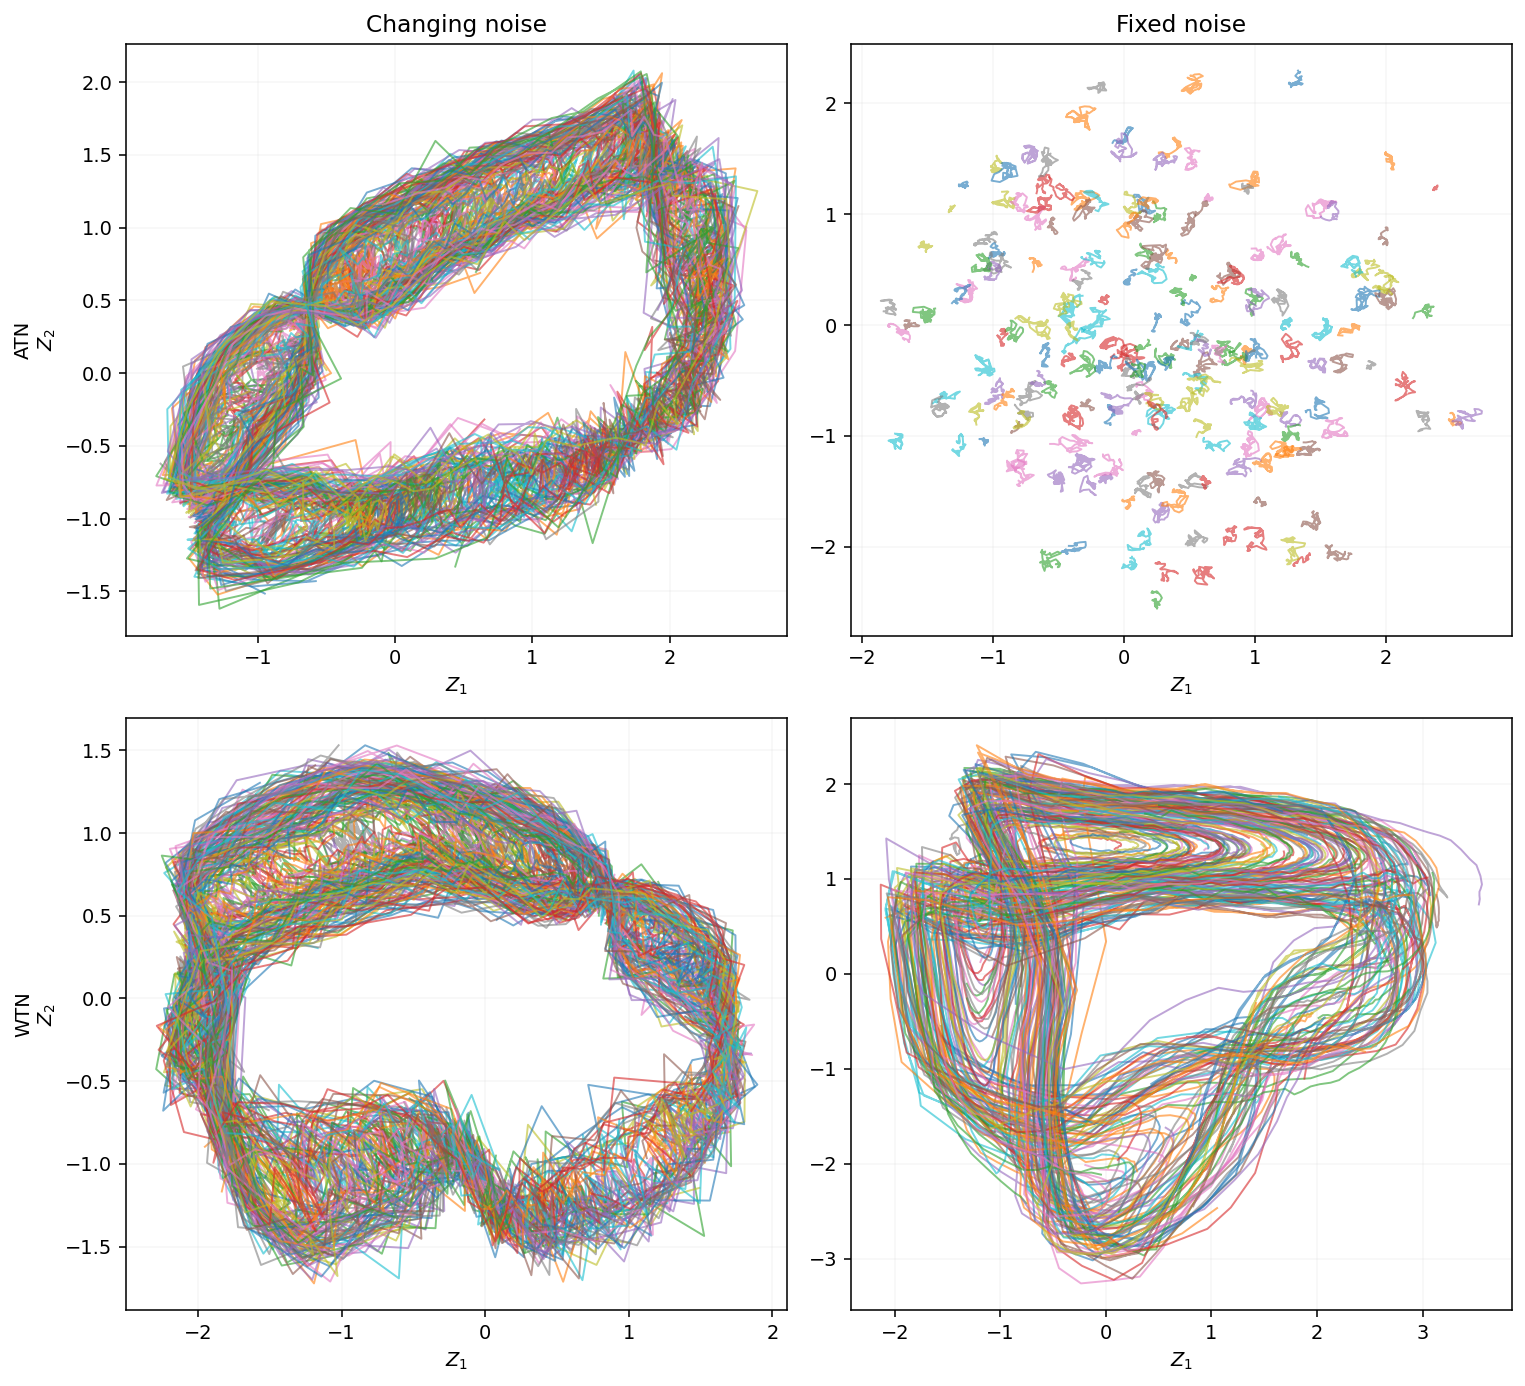

In [20]:
figS1, axesS1 = plt.subplots(2, 2, figsize=(11, 10), dpi=140)
traj_cols, traj_col_titles = ["changing", "fixed"], ["Changing noise", "Fixed noise"]
n_traj = 200
rng = np.random.default_rng(1)

for ri, neg_mode in enumerate(rows):
    for ci, cond in enumerate(traj_cols):
        ax = axesS1[ri, ci]
        model, p = _load_checkpoint(CKPT[(neg_mode, cond)])
        noisy = add_ou_noise_per_trajectory(data_clean, sigma=float(p["sigma"]), ou_alpha=float(p["ou_alpha"]),
                                             clip=(0.0, 1.0), seed=int(p["noise_seed"]), init="stationary")
        zx_flat, numD = encode_dataset(model, noisy, num_frames=int(p["num_frames"]), device=DEVICE)
        zx_flat = zx_flat.numpy()
        n_trials = zx_flat.shape[0] // numD
        zx_3d = zx_flat.reshape(n_trials, numD, -1)
        idx = rng.choice(n_trials, size=min(n_traj, n_trials), replace=False)
        cmap = plt.cm.tab10
        for k, ti in enumerate(idx):
            traj = zx_3d[ti]
            ax.plot(traj[:, 0], traj[:, 1], color=cmap(k % 10), alpha=0.6, lw=1.0, rasterized=True)
        if ri == 0: ax.set_title(traj_col_titles[ci])
        if ci == 0: ax.set_ylabel(f"{row_labels[ri]}\n$Z_2$")
        ax.set_xlabel("$Z_1$"); ax.grid(alpha=0.1)

figS1.tight_layout()
figS1.savefig(FIGURE_DIR / "figS1_pendulum_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()


## Fig 4 / Fig S3: RMSE vs correlation time τ (T=17)

Probe RMSE as a function of the noise's temporal correlation time τ, at
fixed trajectory length T=17, for several noise strengths. ATN degrades
monotonically as τ grows; WTN stays low at both ends of the τ range and
peaks only at intermediate τ ≈ T.

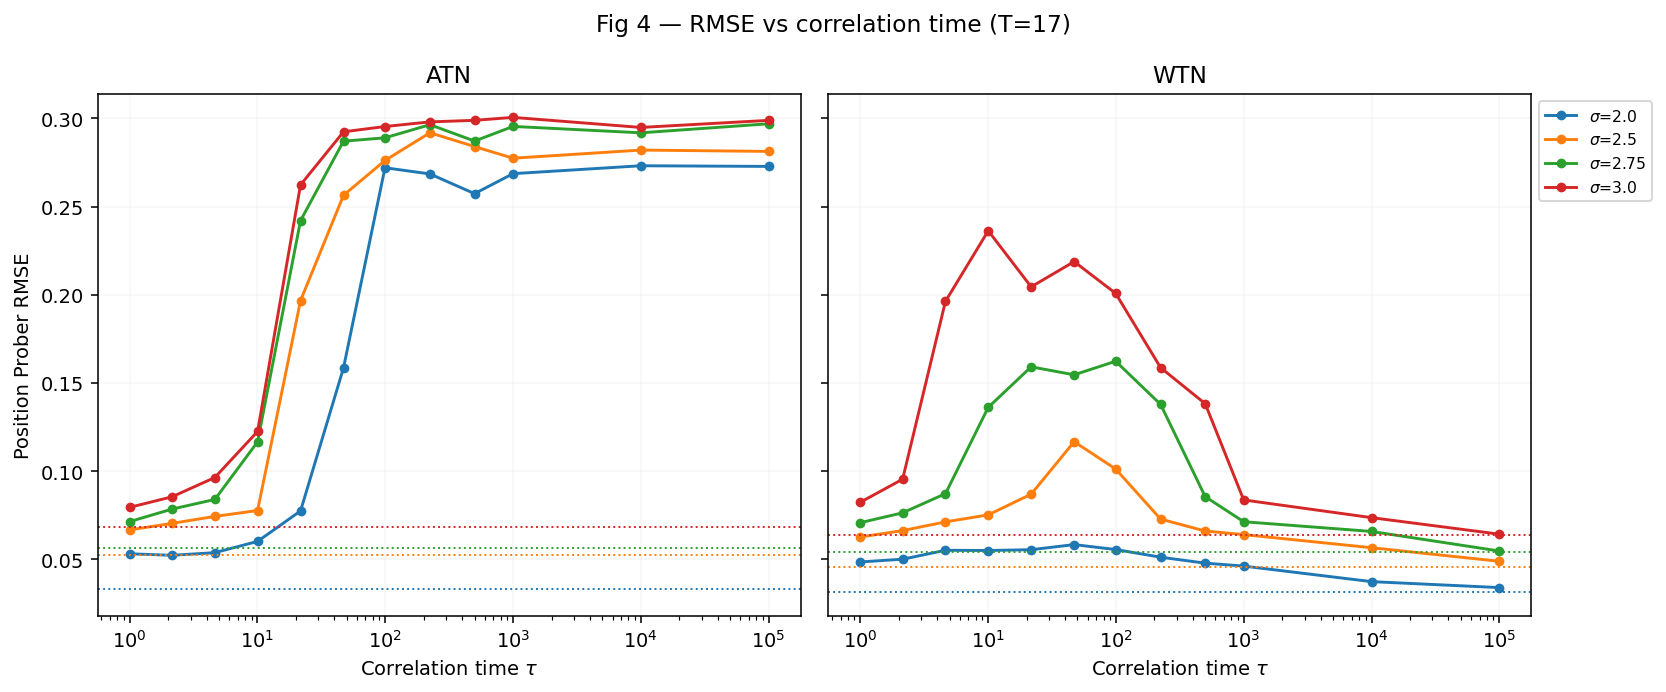

In [21]:
sigmas = sorted(tau_df["noise_sigma"].unique())
cmap = plt.get_cmap("tab10")
sigma_color = {s: cmap(i % 10) for i, s in enumerate(sigmas)}


def make_tau_sweep_fig(agg_mode, out_name, title, k=5):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=140, sharey=True)
    for ax, variant in zip(axes, ["baseline", "baseline_traj_neg"]):
        sub_v = tau_df.query("variant == @variant and T == @T_FIXED")
        for sigma in sigmas:
            ou = sub_v[(sub_v["noise_sigma"] == sigma) & (sub_v["noise_alpha"] > 0) & (sub_v["noise_alpha"] < 1)]
            if len(ou) == 0:
                continue
            if agg_mode == "min":
                agg = min_agg(ou, ["tau"]).sort_values("tau")
                ax.plot(agg["tau"], agg["rmse_enc"] / NORM, "o-", color=sigma_color[sigma], label=f"$\\sigma$={sigma}", markersize=4)
            else:
                agg = kmin_range_agg(ou, ["tau"], k=k).sort_values("tau")
                ax.fill_between(agg["tau"], agg["lo"] / NORM, agg["hi"] / NORM, color=sigma_color[sigma], alpha=0.15)
                ax.plot(agg["tau"], agg["median"] / NORM, "o-", color=sigma_color[sigma], label=f"$\\sigma$={sigma}", markersize=4)
            wn = sub_v[(sub_v["noise_sigma"] == sigma) & (sub_v["noise_alpha"] == 0)]
            if len(wn) > 0:
                ax.axhline(wn["rmse_enc"].min() / NORM, color=sigma_color[sigma], ls=":", lw=1)
        ax.set_xscale("log"); ax.set_xlabel(r"Correlation time $\tau$")
        ax.set_title(VLABEL[variant]); ax.grid(alpha=0.1)
    axes[0].set_ylabel("Position Prober RMSE")
    axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"{out_name}.png", dpi=150, bbox_inches="tight")
    plt.show()


T_FIXED = 17
make_tau_sweep_fig("min", "fig4_tau_sweep", f"Fig 4 — RMSE vs correlation time (T={T_FIXED})")


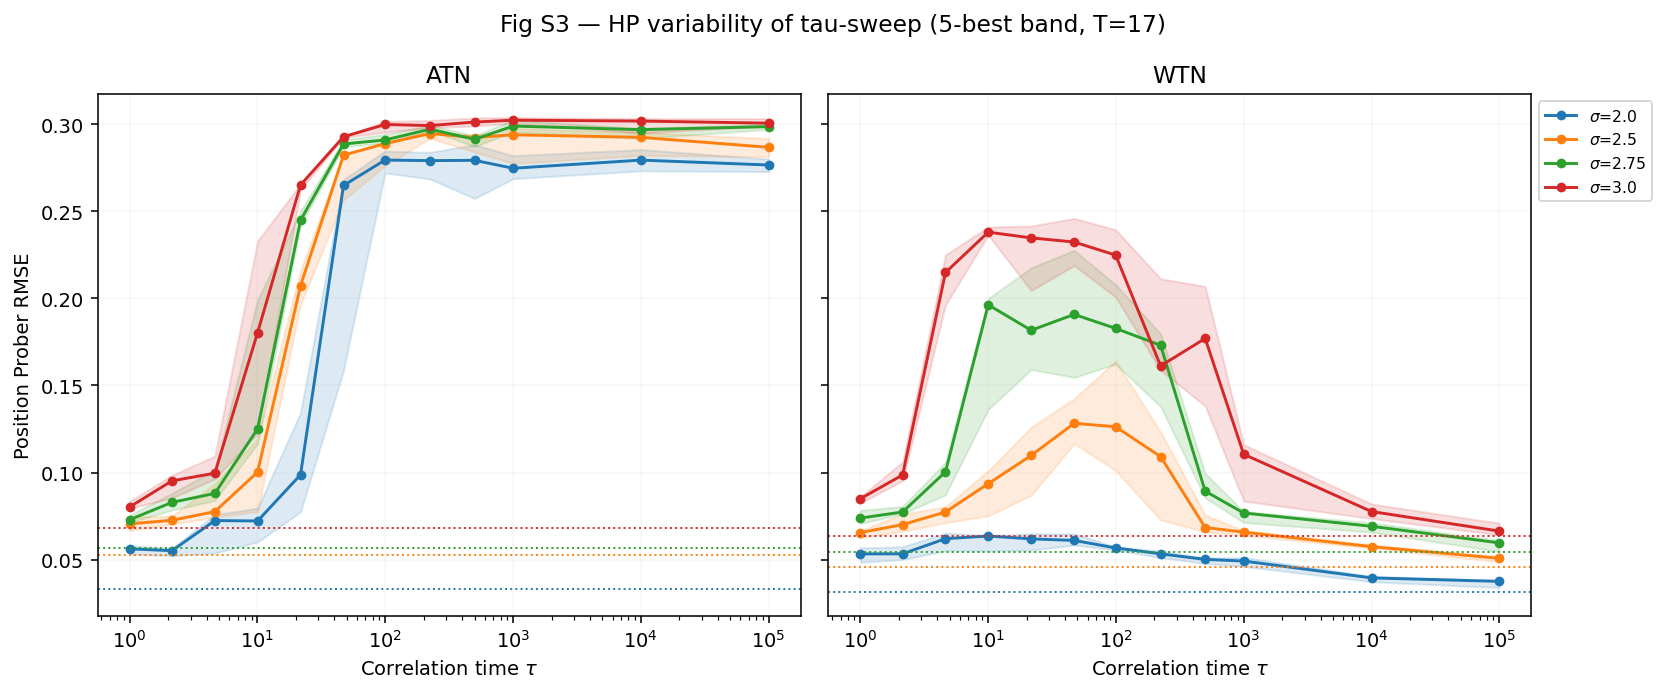

In [22]:
make_tau_sweep_fig("kmin_range", "figS3_tau_hp_variability", f"Fig S3 — HP variability of tau-sweep (5-best band, T={T_FIXED})")

## Fig 5: (τ, T) phase diagram + peak-error scaling

The (τ, T) failure landscape for ATN and WTN, plus the worst-case
(peak-over-τ) RMSE as trajectory length T grows. ATN's failure region
persists at every T; WTN's peak error shrinks as T increases, approaching
the supervised baseline (inset: excess error vs. T, log-log).

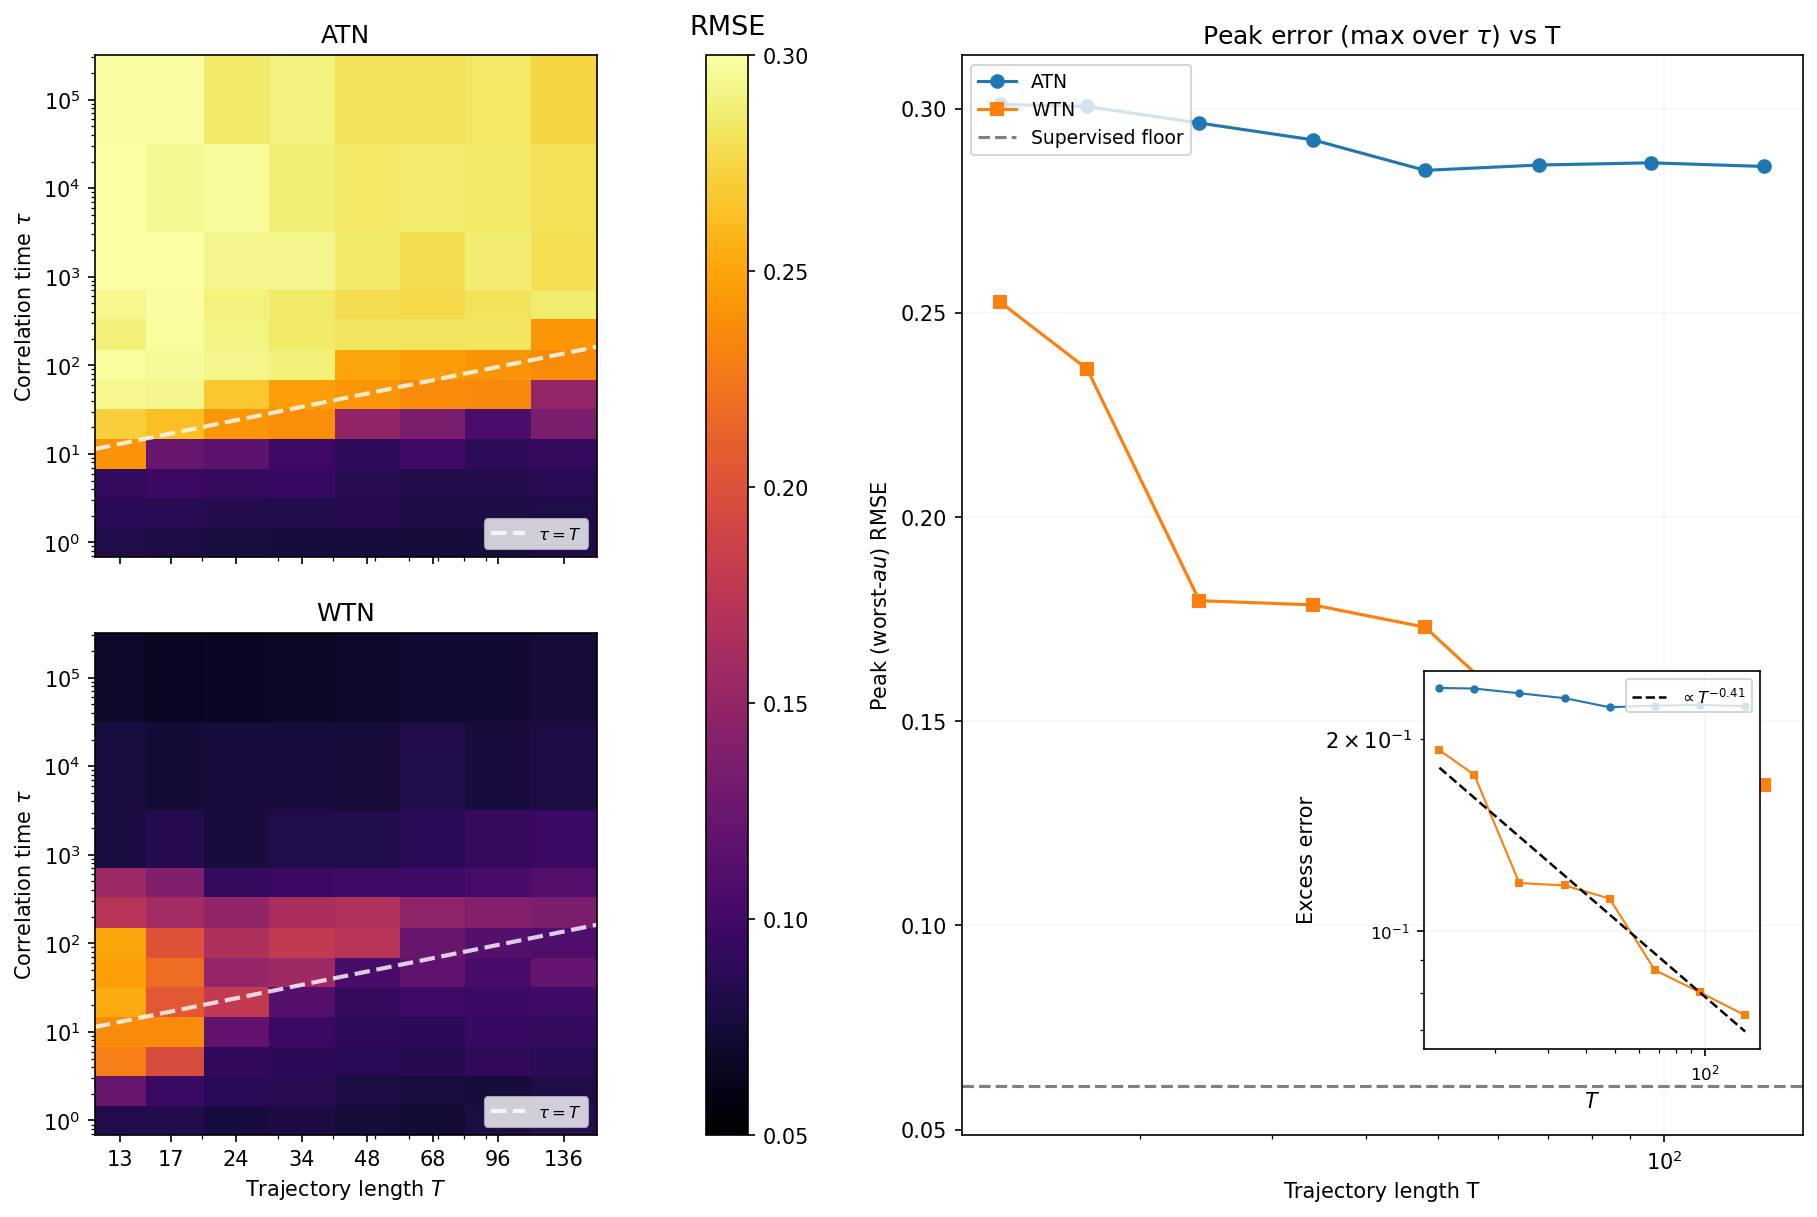

In [23]:
from matplotlib.gridspec import GridSpec

SIGMA_PD = 3.0
T_LIST = [13, 17, 24, 34, 48, 68, 96, 136]
PD_VMIN, PD_VMAX = 0.05, 0.30

fig5 = plt.figure(figsize=(12, 8), dpi=150, constrained_layout=True)
gs = GridSpec(2, 3, figure=fig5, width_ratios=[1, 0.07, 1.4], height_ratios=[1, 1], wspace=0.1)
ax_a = fig5.add_subplot(gs[0, 0])
ax_b = fig5.add_subplot(gs[1, 0], sharex=ax_a, sharey=ax_a)
ax_cb = fig5.add_subplot(gs[:, 1])
ax_c = fig5.add_subplot(gs[:, 2])


def _log_edges(vals):
    lv = np.log(vals)
    mids = (lv[:-1] + lv[1:]) / 2
    lo = lv[0] - (lv[1] - lv[0]) / 2
    hi = lv[-1] + (lv[-1] - lv[-2]) / 2
    return np.exp(np.concatenate([[lo], mids, [hi]]))


def phase_grid(variant):
    sub = tau_df.query("variant == @variant and noise_sigma == @SIGMA_PD and T in @T_LIST").copy()
    sub = sub[(sub["noise_alpha"] > 0) & (sub["noise_alpha"] < 1)]
    agg = min_agg(sub, ["T", "tau"])
    t_vals = np.array(sorted(agg["T"].unique()))
    tau_vals = np.array(sorted(agg["tau"].unique()))
    t_idx = {int(v): i for i, v in enumerate(t_vals)}
    tau_idx = {float(v): i for i, v in enumerate(tau_vals)}
    grid = np.full((len(tau_vals), len(t_vals)), np.nan)
    for _, row in agg.iterrows():
        grid[tau_idx[row["tau"]], t_idx[int(row["T"])]] = row["rmse_enc"] / NORM
    return t_vals, tau_vals, _log_edges(t_vals), _log_edges(tau_vals), grid


def _draw_pd(ax, t_edges, tau_edges, grid, title):
    pcm = ax.pcolormesh(t_edges, tau_edges, grid, cmap="inferno", vmin=PD_VMIN, vmax=PD_VMAX, shading="flat")
    ref = np.array([max(t_edges[0], tau_edges[0]), min(t_edges[-1], tau_edges[-1])])
    ax.plot(ref, ref, ls="--", color="white", lw=2.0, alpha=0.8, label=r"$\tau=T$")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(T_LIST); ax.set_xticklabels([str(v) for v in T_LIST])
    ax.set_ylabel(r"Correlation time $\tau$")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)
    return pcm


t_vals, tau_vals, t_edges, tau_edges, grid_a = phase_grid("baseline")
_, _, _, _, grid_b = phase_grid("baseline_traj_neg")
pcm_a = _draw_pd(ax_a, t_edges, tau_edges, grid_a, "ATN")
_draw_pd(ax_b, t_edges, tau_edges, grid_b, "WTN")
ax_a.set_xlabel(""); ax_a.tick_params(labelbottom=False)
ax_a.set_box_aspect(1); ax_b.set_box_aspect(1)
ax_b.set_xlabel("Trajectory length $T$")
fig5.colorbar(pcm_a, cax=ax_cb, orientation="vertical")
ax_cb.set_title("RMSE", fontsize=13, pad=10)

# Panel C: max-over-tau vs T for both variants (tab10 colors), + supervised floor + inset
sup_floor = dot_sup_df[dot_sup_df["sigma"] == SIGMA_PD]["rmse_enc"].min() / NORM
peaks = {}
for variant, color, marker in [("baseline", "tab:blue", "o"), ("baseline_traj_neg", "tab:orange", "s")]:
    sub = tau_df.query("variant == @variant and noise_sigma == @SIGMA_PD and T in @T_LIST").copy()
    sub = sub[(sub["noise_alpha"] > 0) & (sub["noise_alpha"] < 1)]
    peak = min_agg(sub, ["T", "tau"]).groupby("T")["rmse_enc"].max().reset_index().sort_values("T")
    peaks[variant] = peak
    ax_c.plot(peak["T"], peak["rmse_enc"] / NORM, marker + "-", color=color, label=VLABEL[variant])
ax_c.axhline(sup_floor, color="gray", ls="--", label="Supervised floor")
ax_c.set_xscale("log")
ax_c.set_xlabel("Trajectory length T")
ax_c.set_ylabel("Peak (worst-$\tau$) RMSE")
ax_c.legend(fontsize=9, loc="upper left")
ax_c.grid(alpha=0.1)
ax_c.set_title(r"Peak error (max over $\tau$) vs T")

# Inset: floor-subtracted excess peak RMSE, log-log, power-law fit (WTN)
ax_ins = ax_c.inset_axes([0.55, 0.08, 0.40, 0.35])
for variant, color, marker in [("baseline", "tab:blue", "o"), ("baseline_traj_neg", "tab:orange", "s")]:
    peak = peaks[variant]
    exc = peak["rmse_enc"].to_numpy() / NORM - sup_floor
    T_arr = peak["T"].to_numpy()
    mask = exc > 0
    if mask.sum() < 2:
        continue
    ax_ins.plot(T_arr[mask], exc[mask], marker, color=color, markersize=3, ls="-", lw=1)
    if variant == "baseline_traj_neg":
        slope, icept = np.polyfit(np.log(T_arr[mask]), np.log(exc[mask]), 1)
        T_fit = np.geomspace(T_arr[mask].min(), T_arr[mask].max(), 60)
        ax_ins.plot(T_fit, np.exp(icept) * T_fit ** slope, ls="--", color="k", lw=1.2,
                   label=rf"$\propto T^{{{slope:.2f}}}$")
ax_ins.set_xscale("log"); ax_ins.set_yscale("log")
ax_ins.set_xlabel("$T$", fontsize=10); ax_ins.set_ylabel("Excess error", fontsize=10)
ax_ins.tick_params(labelsize=8)
ax_ins.legend(fontsize=8, loc="upper right")
ax_ins.grid(alpha=0.15)

fig5.savefig(FIGURE_DIR / "fig5_phase_diagram.png", dpi=150, bbox_inches="tight")
plt.show()


## Fig S4: τ/T rescaling collapse

The same τ-sweep data, rescaled by trajectory length T. ATN's curves for
every T collapse onto a single curve with a transition at τ/T ≈ 1. WTN's
curves do not collapse onto one another; the peak stays near τ ≈ T but
shrinks as T grows.

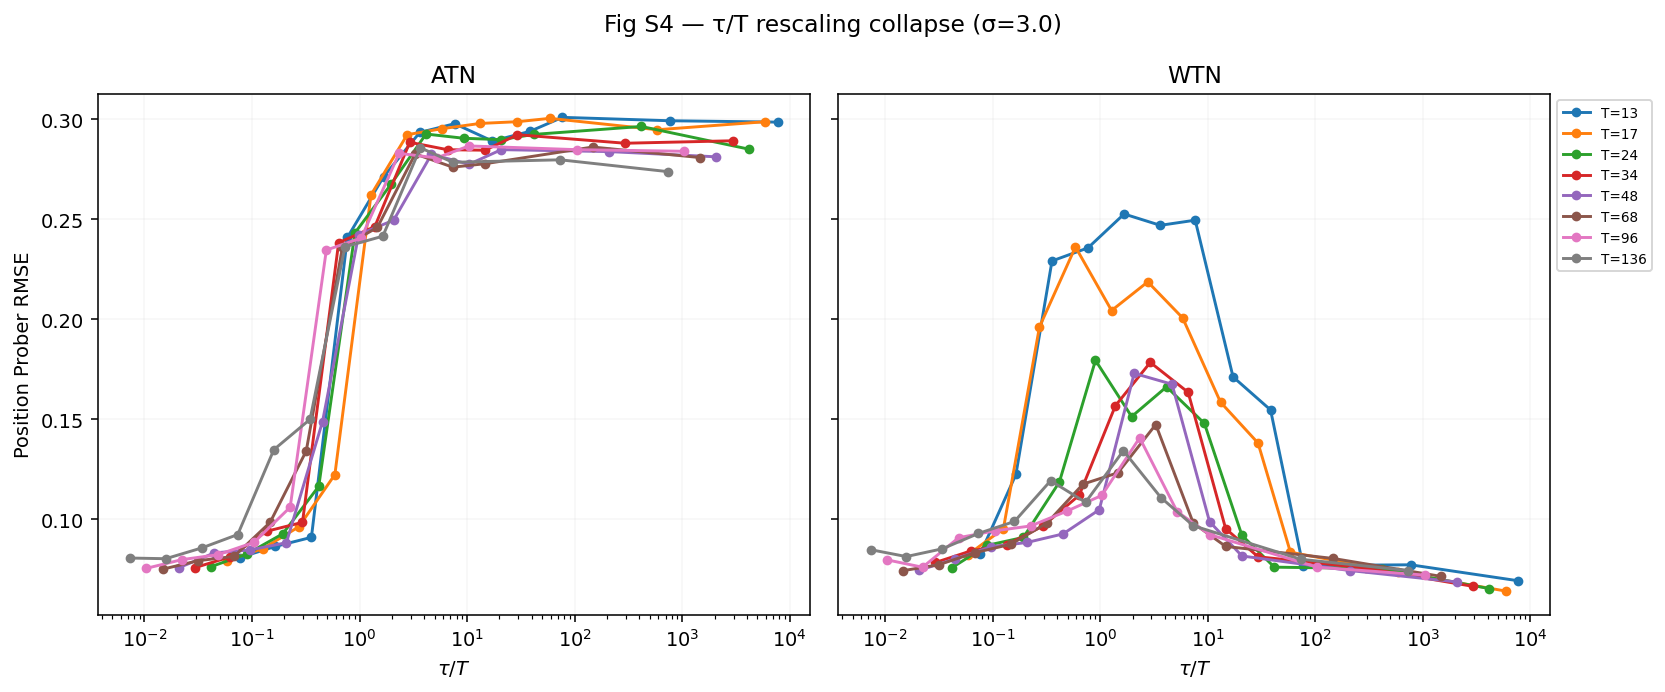

In [24]:
figS4, axesS4 = plt.subplots(1, 2, figsize=(12, 5), dpi=140, sharey=True)
t_colors = {t: plt.cm.tab10(i % 10) for i, t in enumerate(T_LIST)}

for ax, variant in zip(axesS4, ["baseline", "baseline_traj_neg"]):
    for T in T_LIST:
        sub = tau_df.query("variant == @variant and noise_sigma == @SIGMA_PD and T == @T").copy()
        sub = sub[(sub["noise_alpha"] > 0) & (sub["noise_alpha"] < 1)]
        if len(sub) == 0:
            continue
        agg = min_agg(sub, ["tau"]).sort_values("tau")
        ax.plot(agg["tau"] / T, agg["rmse_enc"] / NORM, "o-", color=t_colors[T], label=f"T={T}", markersize=4)
    ax.set_xscale("log"); ax.set_xlabel(r"$\tau / T$"); ax.set_title(VLABEL[variant]); ax.grid(alpha=0.1)
axesS4[0].set_ylabel("Position Prober RMSE")
axesS4[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.0, 1.0))
figS4.suptitle(f"Fig S4 — τ/T rescaling collapse (σ={SIGMA_PD})")
figS4.tight_layout()
figS4.savefig(FIGURE_DIR / "figS4_tau_over_T.png", dpi=150, bbox_inches="tight")
plt.show()


## Fig S5: WTN peak-error power-law scaling

How the worst-case (peak-over-τ) WTN error decays with trajectory length T,
for several noise strengths, with 68% bootstrap confidence intervals. The
excess error above the supervised baseline follows an approximate power law
in T, decaying faster at lower noise strength.

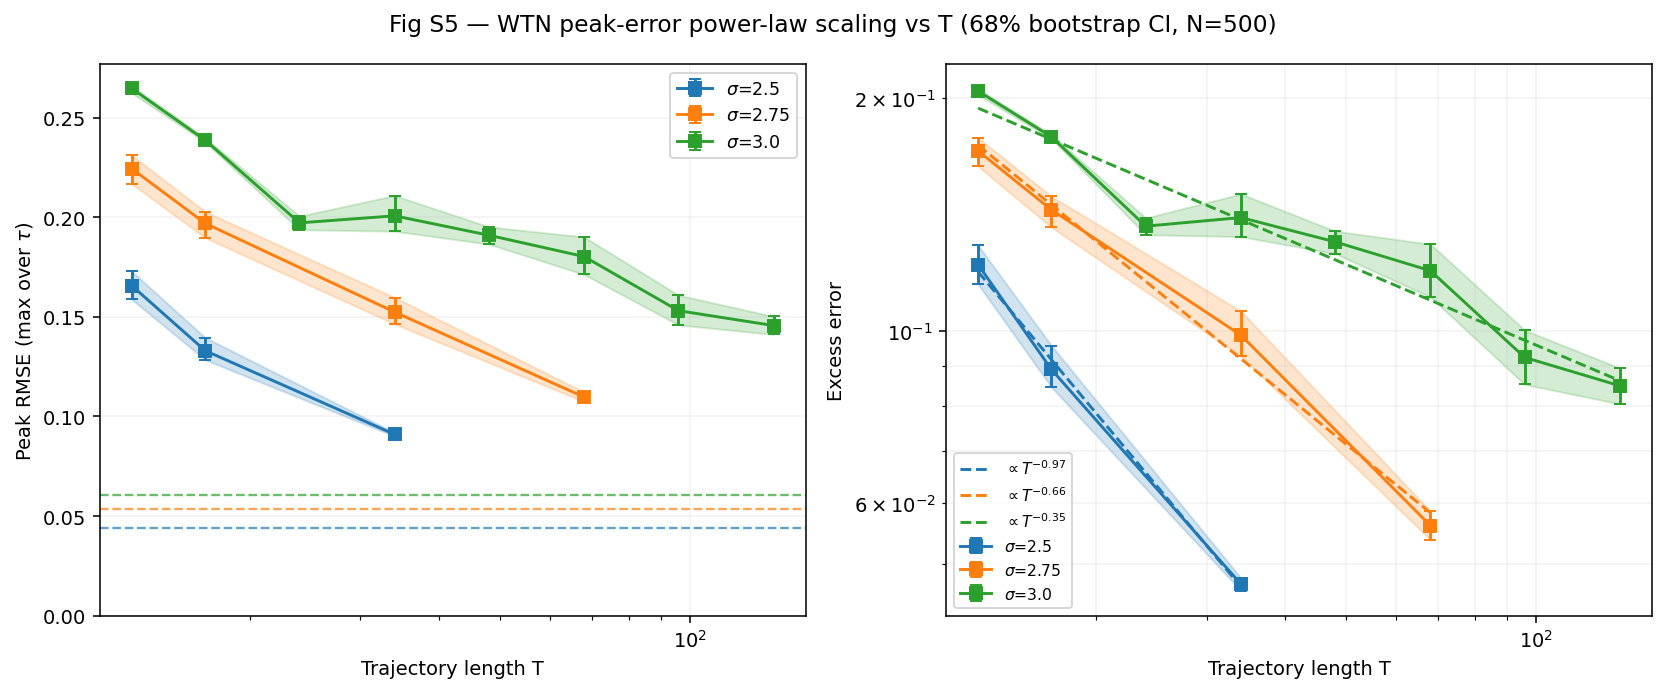

In [25]:
MS_SIGMAS = {2.50: [13, 17, 24, 34, 48], 2.75: [13, 17, 24, 34, 48, 68], 3.00: [13, 17, 24, 34, 48, 68, 96, 136]}
MS_K_MIN, MS_N_BOOT, MS_BOOT_CI, MS_BOOT_SEED = 5, 500, 68, 0
figS5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(12, 5), dpi=140)
ms_colors = {s: plt.cm.tab10(i) for i, s in enumerate(MS_SIGMAS)}


def _boot_peaks(kmin_cells, T, n_boot, rng):
    """Bootstrap the peak-over-tau RMSE: resample each (T, tau) cell's 5-best
    trials with replacement, average, take the max across tau; repeat n_boot
    times to get a distribution of the peak (paper: 68% CI, N=500 resamples)."""
    tau_grid = sorted(tau for (t, tau) in kmin_cells if t == T)
    if len(tau_grid) < 2:
        return np.full(n_boot, np.nan)
    cell_vals = [kmin_cells[(T, tau)] for tau in tau_grid]
    peak = np.empty(n_boot)
    for b in range(n_boot):
        curve = np.array([np.mean(rng.choice(v, size=len(v), replace=True)) for v in cell_vals])
        peak[b] = curve[int(np.argmax(curve))]
    return peak


rng = np.random.default_rng(MS_BOOT_SEED)
lo_p, hi_p = (100 - MS_BOOT_CI) / 2, 100 - (100 - MS_BOOT_CI) / 2

for sigma, t_list in MS_SIGMAS.items():
    sub = tau_df.query("variant == \'baseline_traj_neg\' and noise_sigma == @sigma and T in @t_list").copy()
    sub = sub[(sub["noise_alpha"] > 0) & (sub["noise_alpha"] < 1)]

    kmin_cells = {}
    for (T, tau), grp in sub.groupby(["T", "tau"]):
        kmin_cells[(int(T), float(tau))] = grp["rmse_enc"].dropna().nsmallest(MS_K_MIN).to_numpy()

    t_vals = sorted(set(t for t, _ in kmin_cells) & set(t_list))
    med, lo, hi = [], [], []
    for T in t_vals:
        pr = _boot_peaks(kmin_cells, T, MS_N_BOOT, rng)
        med.append(np.nanmedian(pr)); lo.append(np.nanpercentile(pr, lo_p)); hi.append(np.nanpercentile(pr, hi_p))
    T_arr, med, lo, hi = np.array(t_vals), np.array(med), np.array(lo), np.array(hi)
    color = ms_colors[sigma]
    floor = dot_sup_df[dot_sup_df["sigma"] == sigma]["rmse_enc"].min() / NORM

    ax5a.fill_between(T_arr, lo / NORM, hi / NORM, color=color, alpha=0.2)
    ax5a.errorbar(T_arr, med / NORM, yerr=[np.maximum(0, med - lo) / NORM, np.maximum(0, hi - med) / NORM],
                 color=color, marker="s", ls="-", capsize=3, label=f"$\\sigma$={sigma}", zorder=3)
    ax5a.axhline(floor, color=color, ls="--", lw=1.2, alpha=0.7)

    exc_med, exc_lo, exc_hi = med / NORM - floor, lo / NORM - floor, hi / NORM - floor
    eps = 1e-9
    ax5b.fill_between(T_arr, np.maximum(eps, exc_lo), np.maximum(eps, exc_hi), color=color, alpha=0.2)
    ax5b.errorbar(T_arr, np.maximum(eps, exc_med),
                 yerr=[np.maximum(0, exc_med - exc_lo), np.maximum(0, exc_hi - exc_med)],
                 color=color, marker="s", ls="-", capsize=3, label=f"$\\sigma$={sigma}", zorder=3)
    valid = exc_med > 0
    if valid.sum() >= 2:
        slope, icept = np.polyfit(np.log(T_arr[valid]), np.log(exc_med[valid]), 1)
        T_fit = np.geomspace(T_arr[valid].min(), T_arr[valid].max(), 60)
        ax5b.plot(T_fit, np.exp(icept) * T_fit ** slope, color=color, ls="--", lw=1.5,
                 label=rf"$\propto T^{{{slope:.2f}}}$")

ax5a.set_xscale("log"); ax5a.set_xlabel("Trajectory length T"); ax5a.set_ylabel(r"Peak RMSE (max over $\tau$)")
ax5a.legend(fontsize=9); ax5a.grid(alpha=0.15); ax5a.set_ylim(bottom=0)
ax5b.set_xscale("log"); ax5b.set_yscale("log"); ax5b.set_xlabel("Trajectory length T")
ax5b.set_ylabel("Excess error"); ax5b.legend(fontsize=8, loc="lower left"); ax5b.grid(alpha=0.15, which="both")
figS5.suptitle(f"Fig S5 — WTN peak-error power-law scaling vs T ({MS_BOOT_CI}% bootstrap CI, N={MS_N_BOOT})")
figS5.tight_layout()
figS5.savefig(FIGURE_DIR / "figS5_power_law.png", dpi=150, bbox_inches="tight")
plt.show()


## Fig S6: example frames

Example frames from both datasets across several timesteps, under clean,
fixed-noise, and changing-noise conditions — illustrating the visual
difference between the two noise regimes studied throughout the paper.

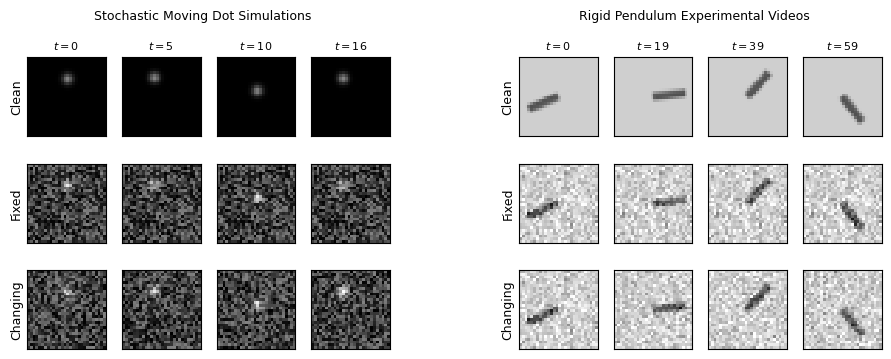

Saved -> Figures/combined_filmstrip.{pdf,png}


In [26]:
# ── params (from intro_figures.ipynb) ──────────────────────────────────────
DOT_SEED, DOT_NOISE_SEED = 7, 42
DOT_N_STEPS, DOT_NOISE_LEVEL, DOT_N_FRAMES = 17, 1.0, 4
DOT_FRAME_IDX = np.linspace(0, DOT_N_STEPS - 1, DOT_N_FRAMES, dtype=int).tolist()
DOT_VMAX_MODE = "noisy_max"

PEND_TRAJ_IDX, PEND_NOISE_SIGMA, PEND_SEED = 2, 0.1, 0
PEND_N_STEPS, PEND_N_FRAMES = 60, 4
PEND_FRAME_IDX = np.linspace(0, PEND_N_STEPS - 1, PEND_N_FRAMES, dtype=int).tolist()
PEND_VMAX_MODE = "fixed_01"

# ── dot data: one clean trajectory + fixed/changing noise overlays ─────────
torch.manual_seed(DOT_SEED)
_ds = dot_data.ContinuousMotionDataset(size=1, batch_size=1, n_steps=DOT_N_STEPS,
                                       noise=0.0, static_noise=0.0, std=1.3)
with torch.no_grad():
    _dot_sample = _ds.generate_multistep_sample()
dot_frames_clean = _dot_sample.states[0, :, 0, :, :].detach().cpu()
_dot_state_max = dot_frames_clean.max().item()

_g = torch.Generator()
_g.manual_seed(DOT_NOISE_SEED)
_fixed_ov = torch.rand(28, 28, generator=_g) * _dot_state_max
dot_frames_fixed = (dot_frames_clean + DOT_NOISE_LEVEL * _fixed_ov).clamp(min=0.0)

_g.manual_seed(DOT_NOISE_SEED + 1)
_changing_ov = torch.rand(DOT_N_STEPS, 28, 28, generator=_g) * _dot_state_max
dot_frames_changing = (dot_frames_clean + DOT_NOISE_LEVEL * _changing_ov).clamp(min=0.0)

# ── pendulum data: one trajectory + fixed/changing OU noise ────────────────
_traj = data_clean[[PEND_TRAJ_IDX]].float()
pend_frames_clean = _traj[0].reshape(60, 28, 28).cpu()
_pend_fixed = add_ou_noise_per_trajectory(_traj, sigma=PEND_NOISE_SIGMA, ou_alpha=1.0, seed=PEND_SEED)
pend_frames_fixed = _pend_fixed[0].reshape(60, 28, 28).cpu()
_pend_changing = add_ou_noise_per_trajectory(_traj, sigma=PEND_NOISE_SIGMA, ou_alpha=0.0, seed=PEND_SEED)
pend_frames_changing = _pend_changing[0].reshape(60, 28, 28).cpu()

# ── combined filmstrip ──────────────────────────────────────────────────────
if DOT_VMAX_MODE == "clean_peak":
    _vmin, _vmax = 0.0, _dot_state_max
else:
    _vmin = 0.0
    _vmax = max(dot_frames_fixed[DOT_FRAME_IDX].max().item(), dot_frames_changing[DOT_FRAME_IDX].max().item())

if PEND_VMAX_MODE == "clean_range":
    _p_vmin = pend_frames_clean.min().item()
    _p_vmax = pend_frames_clean.max().item()
else:
    _p_vmin, _p_vmax = 0.0, 1.0

_dot_rows = [("Clean", dot_frames_clean), ("Fixed", dot_frames_fixed), ("Changing", dot_frames_changing)]
_pend_rows = [("Clean", pend_frames_clean), ("Fixed", pend_frames_fixed), ("Changing", pend_frames_changing)]

_dot_w = 1.2 * len(DOT_FRAME_IDX)
_pend_w = 1.2 * len(PEND_FRAME_IDX)
fig_combined = plt.figure(figsize=(_dot_w + _pend_w, 4.0))

sf_dot, sf_pend = fig_combined.subfigures(1, 2, width_ratios=[len(DOT_FRAME_IDX), len(PEND_FRAME_IDX)], wspace=0.05)
axes_dot = sf_dot.subplots(3, len(DOT_FRAME_IDX), gridspec_kw=dict(wspace=0.2, hspace=0.12))
axes_pend = sf_pend.subplots(3, len(PEND_FRAME_IDX), gridspec_kw=dict(wspace=0.2, hspace=0.12))

for r, (label, frames) in enumerate(_dot_rows):
    for c, fi in enumerate(DOT_FRAME_IDX):
        ax = axes_dot[r, c]
        ax.imshow(frames[fi].numpy(), cmap="gray", vmin=_vmin, vmax=_vmax, interpolation="nearest", aspect="equal")
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(label, fontsize=9, labelpad=3)
        if r == 0:
            ax.set_title(f"$t={fi}$", fontsize=8)
sf_dot.suptitle("Stochastic Moving Dot Simulations", fontsize=9)

for r, (label, frames) in enumerate(_pend_rows):
    for c, fi in enumerate(PEND_FRAME_IDX):
        ax = axes_pend[r, c]
        ax.imshow(frames[fi].numpy().reshape(28, 28), cmap="gray", vmin=_p_vmin, vmax=_p_vmax, interpolation="nearest", aspect="equal")
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(label, fontsize=9.0, labelpad=3)
        if r == 0:
            ax.set_title(f"$t={fi}$", fontsize=8)
sf_pend.suptitle("Rigid Pendulum Experimental Videos", fontsize=9)

fig_combined.savefig(FIGURE_DIR / "combined_filmstrip.pdf", bbox_inches="tight", dpi=150)
fig_combined.savefig(FIGURE_DIR / "combined_filmstrip.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved -> Figures/combined_filmstrip.{pdf,png}")
